# Análisis del flujo de muones — versión revisada
**Unidades:** G en m² sr; flujo en m⁻² s⁻¹ sr⁻¹. La incertidumbre total se utiliza para el flujo absoluto. Para diferencias respecto a la referencia se propagan covarianzas de eficiencias comunes, que se cancelan. La incertidumbre estadística de la mediana se estima aproximadamente; la significancia local no es una prueba exacta.

**Precauciones:** No se han cuantificado errores de exposición ni incertidumbre geométrica. Las campañas 5–6 tienen resolución nativa de 10 min. Se debe ejecutar todo el notebook en orden y volver a verificar la lista de candidatos.


In [ ]:
# ============================================================
# CELDA 1. IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import os
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy import stats
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d

from tqdm.auto import tqdm
from google.colab import drive

plt.rcParams.update({
    "figure.figsize": (12, 6),
    "font.size": 12,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "savefig.dpi": 300
})

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
# ============================================================
# CELDA 2. CARGA CORRECTA DE LOS DATOS
# ============================================================

drive.mount("/content/drive_tesis")

RUTA_BASE = Path("/content/drive_tesis/MyDrive")

CARPETAS = {
    2: "2-3094min",
    3: "3-10071min",
    4: "4-10064min",
    5: "5-10080min-10min",
    6: "6-10080min-10min"
}

dataframes = {}

for campana, carpeta in CARPETAS.items():

    archivos = sorted(
        (RUTA_BASE / carpeta).rglob("*.txt")
    )

    partes = []

    for archivo in tqdm(archivos, desc=f"Campaña {campana}"):

        datos = pd.read_csv(
            archivo,
            sep=r"\s+",
            header=None,
            dtype=str
        )

        if datos.shape[1] != 9:
            raise ValueError(
                f"{archivo.name}: se encontraron "
                f"{datos.shape[1]} columnas, se esperaban 9."
            )

        datos.columns = [
            "campo_1", "campo_2", "campo_3", "campo_4",
            "campo_5", "campo_6", "campo_7", "campo_8",
            "timestamp"
        ]

        for columna in datos.columns[:8]:
            datos[columna] = pd.to_numeric(
                datos[columna].str.replace(",", ".", regex=False),
                errors="raise"
            )

        datos["archivo_origen"] = archivo.name
        partes.append(datos)

    dataframes[campana] = pd.concat(
        partes, ignore_index=True
    )

    print(
        f"Campaña {campana}: "
        f"{len(archivos)} archivos, "
        f"{len(dataframes[campana]):,} eventos"
    )

df2, df3, df4, df5, df6 = (
    dataframes[i] for i in [2, 3, 4, 5, 6]
)

Mounted at /content/drive_tesis


Campaña 2:   0%|          | 0/3904 [00:00<?, ?it/s]

Campaña 2: 3904 archivos, 914,742 eventos


Campaña 3:   0%|          | 0/4524 [00:00<?, ?it/s]

Campaña 3: 4524 archivos, 1,064,847 eventos


Campaña 4:   0%|          | 0/10064 [00:00<?, ?it/s]

Campaña 4: 10064 archivos, 2,364,491 eventos


Campaña 5:   0%|          | 0/1008 [00:00<?, ?it/s]

Campaña 5: 1008 archivos, 2,374,541 eventos


Campaña 6:   0%|          | 0/1007 [00:00<?, ?it/s]

Campaña 6: 1007 archivos, 2,392,720 eventos


In [ ]:
# ============================================================
# CELDA 3. INSPECCIÓN DE ESTAMPAS TEMPORALES
# ============================================================

for campana, df in dataframes.items():
    print(f"\n{'='*55}")
    print(f"CAMPAÑA {campana}")
    print(f"{'='*55}")

    print("\nPrimeras 5 filas:")
    print(df.head(5).to_string(index=False, header=False))

    print("\nÚltimas 5 filas:")
    print(df.tail(5).to_string(index=False, header=False))


CAMPAÑA 2

Primeras 5 filas:
864.0 932.0 889.0 4095.0 1131.0 831.0 1288.0 0.0 19/09/26--11:53:49,429 Tiempo_Datos_1000.txt
878.0 851.0 880.0 4095.0    1.0 974.0    1.0 1.0 19/09/26--11:53:49,451 Tiempo_Datos_1000.txt
742.0 838.0 878.0 4095.0 1485.0 900.0  741.0 0.0 19/09/26--11:53:49,815 Tiempo_Datos_1000.txt
837.0 901.0 879.0 4095.0 1079.0 903.0 1349.0 1.0 19/09/26--11:53:49,833 Tiempo_Datos_1000.txt
872.0 922.0 887.0 4095.0  396.0 498.0  722.0 0.0 19/09/26--11:53:50,566 Tiempo_Datos_1000.txt

Últimas 5 filas:
806.0 882.0 881.0 4095.0 772.0  808.0  636.0 1.0 19/09/26--11:53:47,768 Tiempo_Datos_999.txt
811.0 872.0 882.0 4095.0 470.0  643.0  667.0 0.0 19/09/26--11:53:48,057 Tiempo_Datos_999.txt
884.0 856.0 828.0 4095.0  80.0    1.0  369.0 1.0 19/09/26--11:53:48,088 Tiempo_Datos_999.txt
795.0 887.0 879.0 4095.0 422.0 1279.0 1366.0 0.0 19/09/26--11:53:48,567 Tiempo_Datos_999.txt
877.0 887.0 835.0 4095.0 624.0  769.0 1658.0 1.0 19/09/26--11:53:49,015 Tiempo_Datos_999.txt

CAMPAÑA 3

Prime

In [ ]:
# ============================================================
# CELDA 4. VALIDACIÓN DE ESTAMPAS TEMPORALES
# ============================================================

formato = r"\d{2}/\d{2}/\d{2}--\d{2}:\d{2}:\d{2},\d{3}"

for campana, df in dataframes.items():

    total = len(df)

    # Validar estructura exacta
    estructura_valida = df["timestamp"].str.fullmatch(formato).fillna(False)

    # Validar que la fecha y hora existan
    fechas = pd.to_datetime(
        df["timestamp"],
        format="%d/%m/%y--%H:%M:%S,%f",
        errors="coerce"
    )

    validos = estructura_valida & fechas.notna()

    # Conservar únicamente eventos válidos
    dataframes[campana] = df.loc[validos].copy().reset_index(drop=True)

    print(
        f"Campaña {campana}: "
        f"{total:,} originales | "
        f"{validos.sum():,} válidos | "
        f"{(~validos).sum():,} descartados"
    )

# Actualizar DataFrames individuales
df2, df3, df4, df5, df6 = (
    dataframes[i] for i in [2, 3, 4, 5, 6]
)

/tmp/ipykernel_837/331433867.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  estructura_valida = df["timestamp"].str.fullmatch(formato).fillna(False)


Campaña 2: 914,742 originales | 913,197 válidos | 1,545 descartados


/tmp/ipykernel_837/331433867.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  estructura_valida = df["timestamp"].str.fullmatch(formato).fillna(False)


Campaña 3: 1,064,847 originales | 1,057,052 válidos | 7,795 descartados


/tmp/ipykernel_837/331433867.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  estructura_valida = df["timestamp"].str.fullmatch(formato).fillna(False)


Campaña 4: 2,364,491 originales | 2,356,626 válidos | 7,865 descartados


/tmp/ipykernel_837/331433867.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  estructura_valida = df["timestamp"].str.fullmatch(formato).fillna(False)


Campaña 5: 2,374,541 originales | 2,337,608 válidos | 36,933 descartados


/tmp/ipykernel_837/331433867.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  estructura_valida = df["timestamp"].str.fullmatch(formato).fillna(False)


Campaña 6: 2,392,720 originales | 2,323,511 válidos | 69,209 descartados


In [ ]:
# ============================================================
# CELDA 5. FLUJO E INCERTIDUMBRE TOTAL
# ============================================================

from scipy.integrate import quad

# 1. ACEPTANCIA GEOMÉTRICA
L = 25.0       # cm
d = 22.75      # cm

def integrando(theta, phi):
    dx = d * np.tan(theta) * np.cos(phi)
    dy = d * np.tan(theta) * np.sin(phi)
    area = max(0, L - abs(dx)) * max(0, L - abs(dy))
    return area * np.cos(theta) * np.sin(theta)

def integral_angular(phi):
    limite = np.arctan(
        L / (d * max(abs(np.cos(phi)), abs(np.sin(phi))))
    )
    return quad(integrando, 0, limite, args=(phi,))[0]

# Simetría del detector cuadrado
G_cm2_sr = 8 * quad(integral_angular, 0, np.pi / 4)[0]
G = G_cm2_sr * 1e-4  # m² sr


# 2. EFICIENCIAS DE LOS CENTELLADORES A -1999.6 V
# Datos del Excel: dobles y triples, respectivamente.

mediciones_HV = {
    "C1": (2025, 1981),
    "C2": (2193, 2174),
    "C4": (2079, 2051)
}

eficiencias_HV = {}

for detector, (dobles, triples) in mediciones_HV.items():
    epsilon = triples / dobles
    sigma = np.sqrt(epsilon * (1 - epsilon) / dobles)
    eficiencias_HV[detector] = (epsilon, sigma)

EPS_CENT = np.prod([v[0] for v in eficiencias_HV.values()])

REL_VAR_CENT = sum(
    (sigma / epsilon)**2
    for epsilon, sigma in eficiencias_HV.values()
)

SIGMA_EPS_CENT = EPS_CENT * np.sqrt(REL_VAR_CENT)


# 3. EFICIENCIA DE LABVIEW
# Comparación con el contador BCD de Jesús.

INICIO_BCD = pd.Timestamp("2026-10-14 07:35:27")
FIN_BCD = pd.Timestamp("2026-10-14 08:12:01")

N_BCD = 190838 - 181863

# Convertir las estampas de todos los DataFrames.
for df in dataframes.values():
    df["fecha_hora"] = pd.to_datetime(
        df["timestamp"],
        format="%d/%m/%y--%H:%M:%S,%f"
    )

# Todos los eventos con timestamp válido, sin cortes TDC/QDC.
N_LV = sum(
    df["fecha_hora"].between(
        INICIO_BCD, FIN_BCD, inclusive="both"
    ).sum()
    for df in dataframes.values()
)

if not (0 < N_LV <= N_BCD):
    raise ValueError(
        f"Revisar intervalo BCD: LabVIEW={N_LV}, BCD={N_BCD}"
    )

EPS_LV = N_LV / N_BCD
SIGMA_EPS_LV = np.sqrt(EPS_LV * (1 - EPS_LV) / N_BCD)


# 4. TIEMPO DE OBSERVACIÓN POR ARCHIVO
# Archivos normales: tiempo nominal.
# Archivos parciales: duración observada + 2/r_local,
# donde r_local se estima con archivos normales vecinos.

def calcular_exposiciones(df, campana):

    nominal = 60.0 if campana in (2, 3, 4) else 600.0

    tabla = (
        df.groupby("archivo_origen")
        .agg(
            N_registros=("fecha_hora", "size"),
            inicio=("fecha_hora", "min"),
            fin=("fecha_hora", "max")
        )
        .reset_index()
    )

    tabla["numero"] = (
        tabla["archivo_origen"]
        .str.extract(r"Tiempo_Datos_(\d+)\.txt")[0]
        .astype(int)
    )

    tabla = tabla.sort_values("numero").reset_index(drop=True)

    tabla["duracion_observada_s"] = (
        tabla["fin"] - tabla["inicio"]
    ).dt.total_seconds()

    # Identificar archivos de duración normal
    normales = tabla["duracion_observada_s"].between(
        0.95 * nominal, nominal + 2
    )

    tabla["tasa_normal"] = np.where(
        normales,
        tabla["N_registros"] / nominal,
        np.nan
    )

    # Tasa de referencia obtenida de archivos vecinos
    tasa_global = tabla["tasa_normal"].median()

    exposiciones = []

    for i, fila in tabla.iterrows():

        if normales.iloc[i]:
            T = nominal
        else:
            vecinos = tabla.iloc[max(0, i-5):i+6]
            tasa_local = vecinos["tasa_normal"].median()

            if not np.isfinite(tasa_local):
                tasa_local = tasa_global

            T = fila["duracion_observada_s"] + 2 / tasa_local
            T = min(T, nominal)

        exposiciones.append(T)

    tabla["T_obs_s"] = exposiciones

    # Archivo con falla de adquisición identificada previamente
    if campana == 2:
        tabla.loc[tabla["numero"] == 1513, "T_obs_s"] = np.nan

    return tabla


exposiciones = {
    campana: calcular_exposiciones(df, campana)
    for campana, df in dataframes.items()
}


# 5. FUNCIONES DEL OBSERVABLE Y SU INCERTIDUMBRE

def calcular_flujo(N, T_obs):
    return N / (T_obs * G * EPS_CENT * EPS_LV)


def calcular_incertidumbre(N, T_obs):

    N = np.asarray(N, dtype=float)
    T_obs = np.asarray(T_obs, dtype=float)

    phi = calcular_flujo(N, T_obs)

    varianza_relativa = (
        1 / np.maximum(N, 1)
        + REL_VAR_CENT
        + (SIGMA_EPS_LV / EPS_LV)**2
    )

    return np.sqrt(
        N / (T_obs * G * EPS_CENT * EPS_LV)**2
        + phi**2 * (REL_VAR_CENT + (SIGMA_EPS_LV / EPS_LV)**2)
    )


# 6. COVARIANZA DE SISTEMÁTICOS COMUNES
REL_VAR_SIST = REL_VAR_CENT + (SIGMA_EPS_LV / EPS_LV)**2

# 7. RESUMEN

print(f"Aceptancia: {G_cm2_sr:.4f} cm² sr")
print(f"           {G:.8f} m² sr")

print("\nEficiencias HV:")
for detector, (eps, sigma) in eficiencias_HV.items():
    print(f"{detector}: {eps:.6f} ± {sigma:.6f}")

print(f"\nEficiencia conjunta: {EPS_CENT:.6f} ± {SIGMA_EPS_CENT:.6f}")

print(f"\nConteo BCD: {N_BCD}")
print(f"Conteo LabVIEW: {N_LV}")
print(f"Eficiencia LabVIEW: {EPS_LV:.6f} ± {SIGMA_EPS_LV:.6f}")

print("\nArchivos y exposiciones calculadas:")
for campana, tabla in exposiciones.items():
    print(f"Campaña {campana}: {len(tabla)} archivos")

Aceptancia: 442.6804 cm² sr
           0.04426804 m² sr

Eficiencias HV:
C1: 0.978272 ± 0.003240
C2: 0.991336 ± 0.001979
C4: 0.986532 ± 0.002528

Eficiencia conjunta: 0.956735 ± 0.004438

Conteo BCD: 8975
Conteo LabVIEW: 8548
Eficiencia LabVIEW: 0.952423 ± 0.002247

Archivos y exposiciones calculadas:
Campaña 2: 3904 archivos
Campaña 3: 4524 archivos
Campaña 4: 10064 archivos
Campaña 5: 1008 archivos
Campaña 6: 1007 archivos


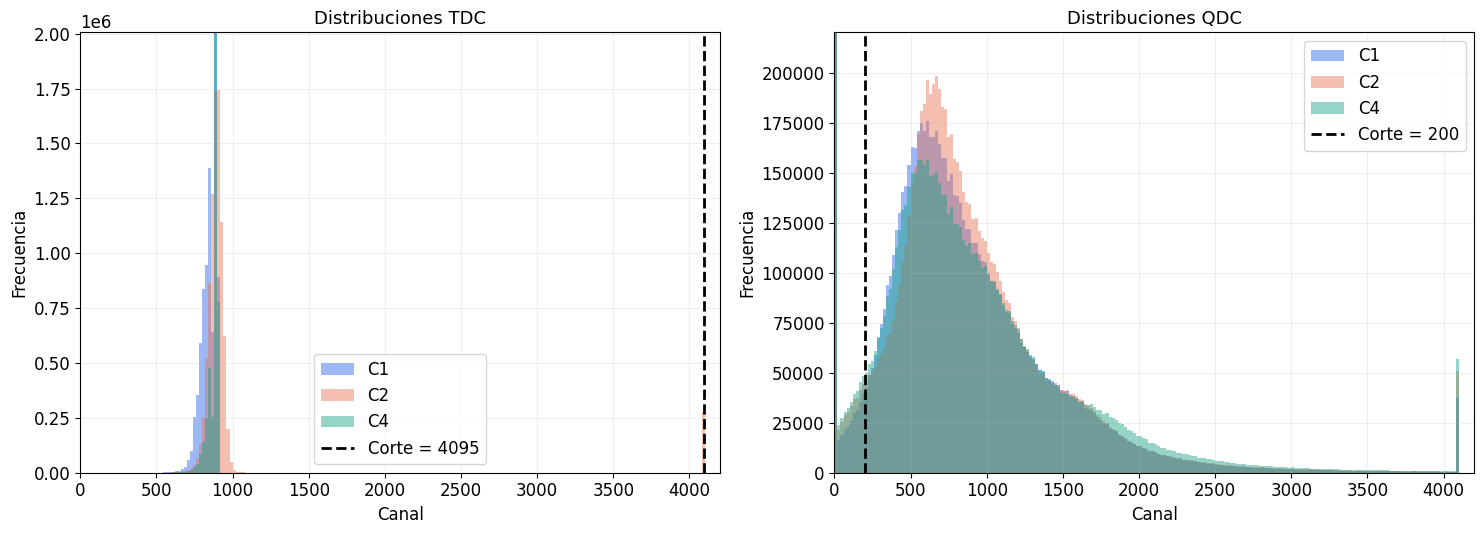

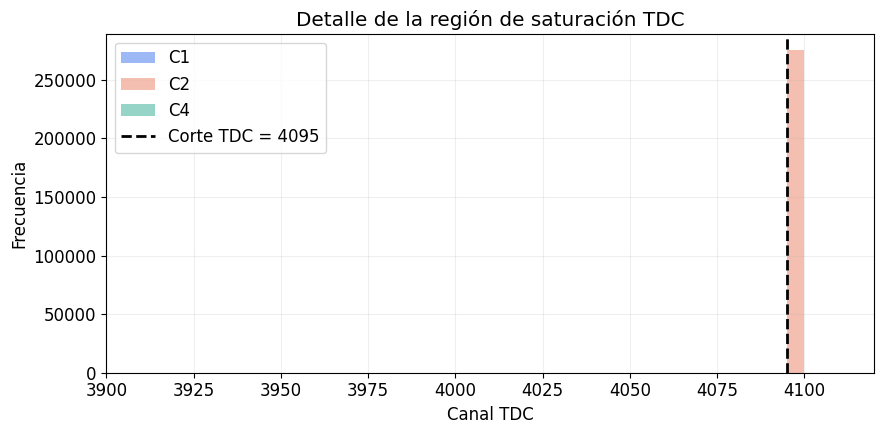


TRIPLES COINCIDENCIAS POR CAMPAÑA
---------------------------------------------
Campaña 2: 804,921 / 913,197 eventos (88.14 %)
Campaña 3: 916,980 / 1,057,052 eventos (86.75 %)
Campaña 4: 2,044,039 / 2,356,626 eventos (86.74 %)
Campaña 5: 2,005,926 / 2,337,608 eventos (85.81 %)
Campaña 6: 2,036,543 / 2,323,511 eventos (87.65 %)


In [ ]:
# ============================================================
# CELDA 6. HISTOGRAMAS TDC Y QDC - TRIPLES COINCIDENCIAS
# ============================================================

TDC = {"C1": "campo_1", "C2": "campo_2", "C4": "campo_3"}
QDC = {"C1": "campo_5", "C2": "campo_6", "C4": "campo_7"}

CORTE_TDC = 4095
CORTE_QDC_C2 = 200

colores = {
    "C1": "#2563EB",  # Azul
    "C2": "#E76F51",  # Coral
    "C4": "#16A085"   # Verde
}

# Reunir los datos de las cinco campañas
datos = pd.concat(
    [dataframes[c] for c in [2, 3, 4, 5, 6]],
    ignore_index=True
)

# ------------------------------------------------------------
# 1. HISTOGRAMAS GENERALES
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

configuraciones = [
    (axes[0], TDC, "Distribuciones TDC", CORTE_TDC),
    (axes[1], QDC, "Distribuciones QDC", CORTE_QDC_C2)
]

for ax, columnas, titulo, corte in configuraciones:

    frecuencias = []
    bins = np.arange(0, 4201, 20)

    for detector, columna in columnas.items():

        valores = datos[columna].dropna()

        conteos, _ = np.histogram(valores, bins=bins)
        frecuencias.extend(conteos[conteos > 0])

        ax.hist(
            valores,
            bins=bins,
            color=colores[detector],
            alpha=0.45,
            label=detector,
            histtype="stepfilled"
        )

    ax.axvline(
        corte,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Corte = {corte}"
    )

    ax.set_ylim(
        0,
        np.percentile(frecuencias, 99) * 1.15
    )

    ax.set_xlim(0, 4200)
    ax.set_title(titulo, fontsize=13)
    ax.set_xlabel("Canal")
    ax.set_ylabel("Frecuencia")
    ax.legend()
    ax.grid(alpha=0.20)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. ACERCAMIENTO AL CORTE TDC = 4095
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 4.5))

for detector, columna in TDC.items():

    ax.hist(
        datos[columna].dropna(),
        bins=np.arange(3900, 4121, 5),
        color=colores[detector],
        alpha=0.45,
        label=detector,
        histtype="stepfilled"
    )

ax.axvline(
    CORTE_TDC,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Corte TDC = 4095"
)

ax.set_xlim(3900, 4120)
ax.set_xlabel("Canal TDC")
ax.set_ylabel("Frecuencia")
ax.set_title("Detalle de la región de saturación TDC")
ax.legend()
ax.grid(alpha=0.20)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. DEFINICIÓN DE TRIPLE COINCIDENCIA
# ------------------------------------------------------------

def seleccionar_triples(df):

    return df.loc[
        (df["campo_1"] < CORTE_TDC) &
        (df["campo_2"] < CORTE_TDC) &
        (df["campo_3"] < CORTE_TDC) &
        (df["campo_6"] > CORTE_QDC_C2)
    ].copy()

# ------------------------------------------------------------
# 4. SELECCIÓN POR CAMPAÑA
# ------------------------------------------------------------

triples = {
    campana: seleccionar_triples(df)
    for campana, df in dataframes.items()
}

print("\nTRIPLES COINCIDENCIAS POR CAMPAÑA")
print("-" * 45)

for campana in [2, 3, 4, 5, 6]:

    total = len(dataframes[campana])
    seleccionados = len(triples[campana])

    print(
        f"Campaña {campana}: "
        f"{seleccionados:,} / {total:,} eventos "
        f"({100 * seleccionados / total:.2f} %)"
    )

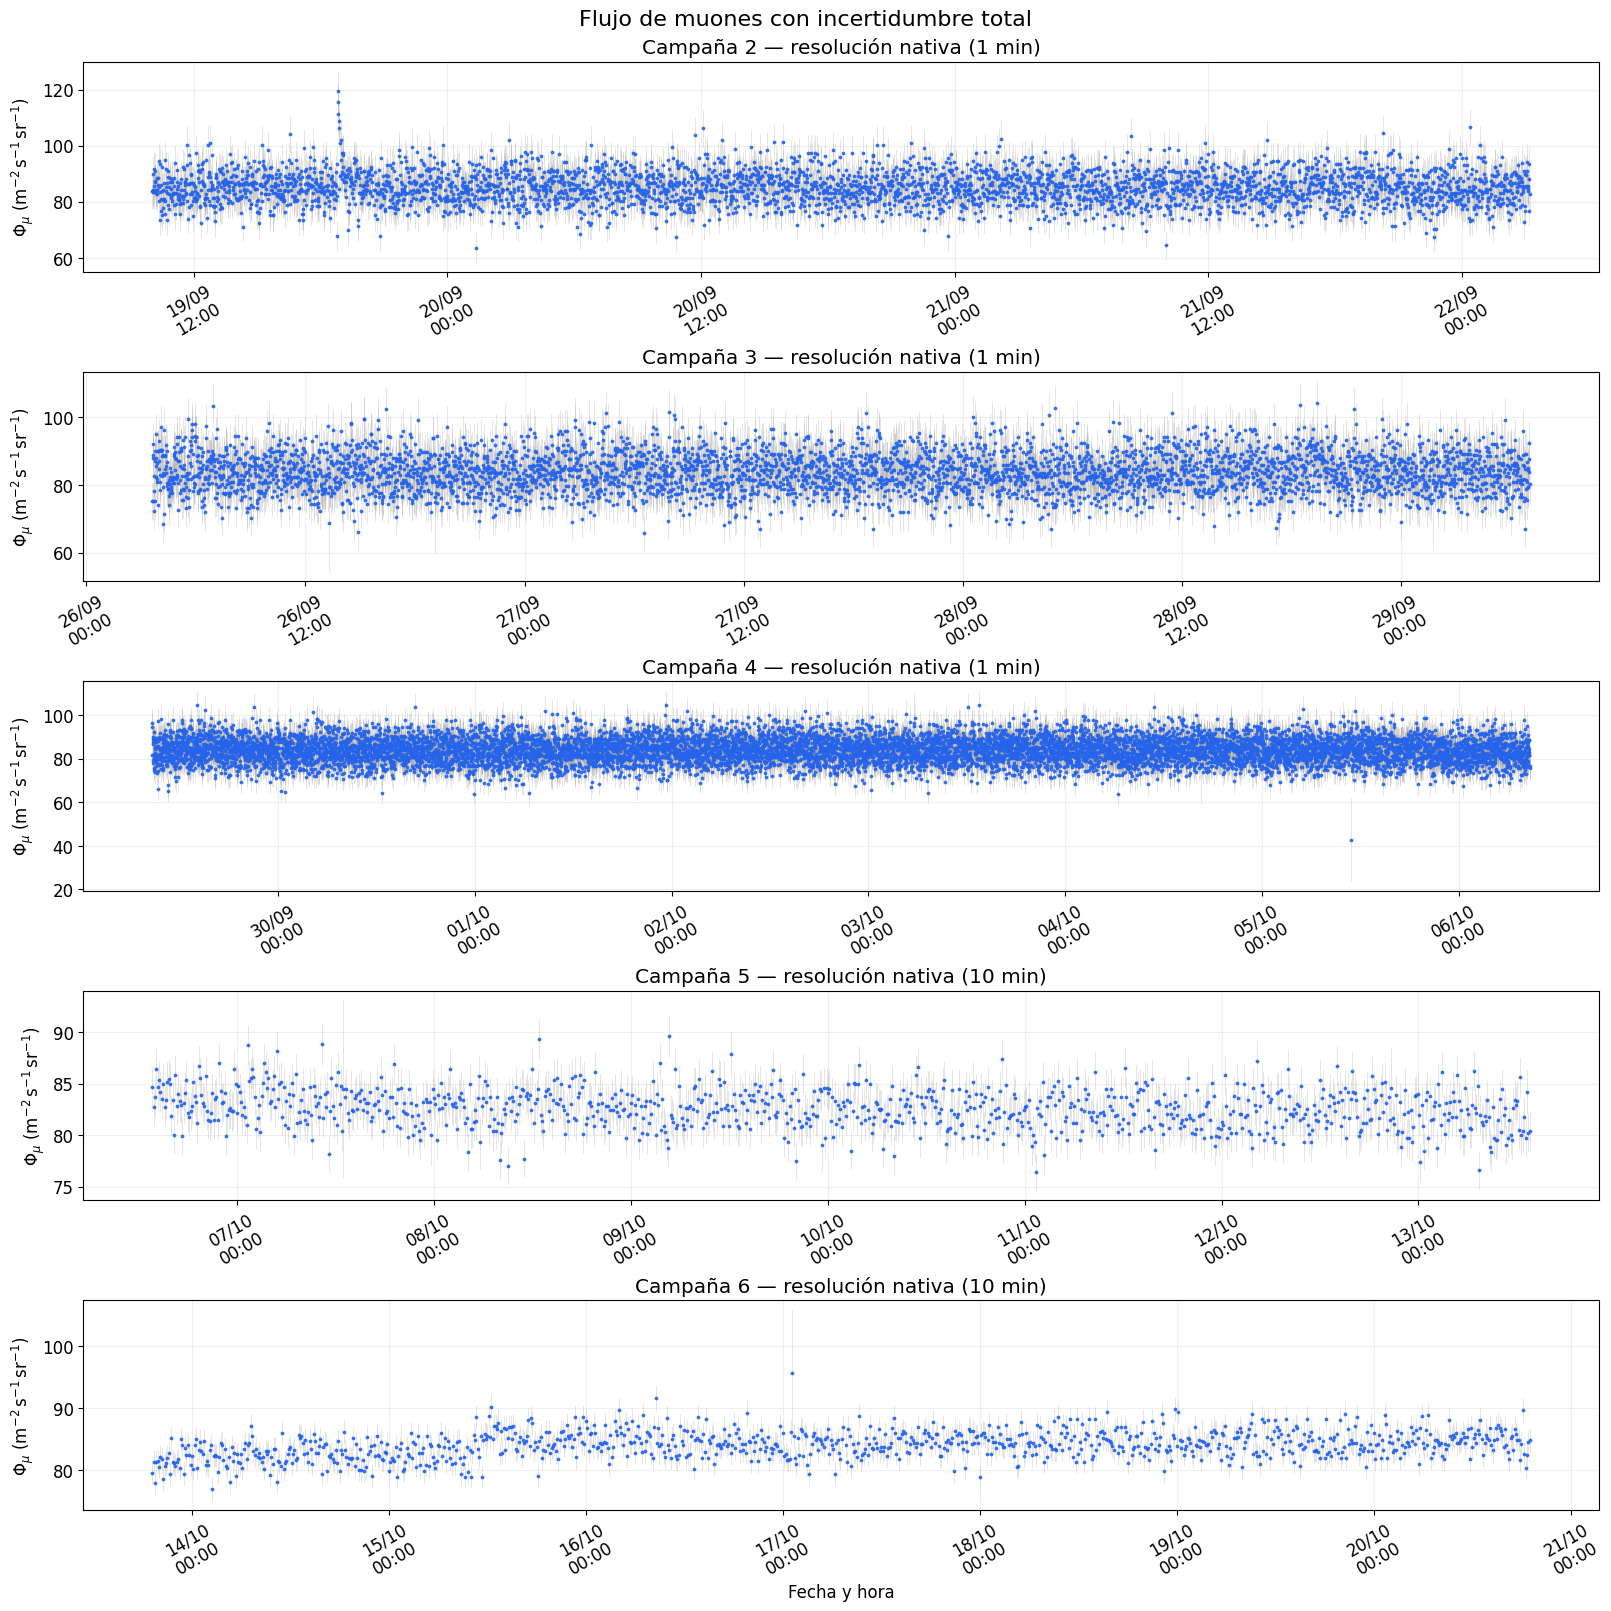

In [ ]:
# ============================================================
# CELDA 7. FLUJO DE MUONES - RESOLUCIÓN NATIVA
# ============================================================

serie_flujo = []

for campana in [2, 3, 4, 5, 6]:

    # Conteos que cumplen los cortes TDC y QDC
    conteos = (
        triples[campana]
        .groupby("archivo_origen")
        .size()
        .rename("N_mu")
    )

    # Exposiciones calculadas en la celda 5
    tabla = exposiciones[campana].copy()

    tabla["N_mu"] = (
        tabla["archivo_origen"]
        .map(conteos)
        .fillna(0)
        .astype(int)
    )

    # Excluir archivos sin exposición válida
    tabla = tabla.loc[
        tabla["T_obs_s"].notna() &
        (tabla["T_obs_s"] > 0)
    ].copy()

    tabla["campana"] = campana

    # Centro temporal de cada intervalo
    tabla["timestamp"] = (
        tabla["inicio"]
        + (tabla["fin"] - tabla["inicio"]) / 2
    )

    # Flujo e incertidumbre total
    tabla["Phi_mu"] = calcular_flujo(
        tabla["N_mu"],
        tabla["T_obs_s"]
    )

    # Presupuesto completo, incluso si N_mu = 0.
    tabla["sigma_Phi_mu"] = calcular_incertidumbre(
        tabla["N_mu"], tabla["T_obs_s"]
    )

    serie_flujo.append(tabla)

serie_flujo = pd.concat(
    serie_flujo,
    ignore_index=True
).sort_values(["campana", "timestamp"])

# ------------------------------------------------------------
# GRÁFICAS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    5, 1,
    figsize=(16, 16),
    constrained_layout=True
)

for ax, campana in zip(axes, [2, 3, 4, 5, 6]):

    df_plot = serie_flujo.loc[
        serie_flujo["campana"] == campana
    ].sort_values("timestamp")

    # Barras de incertidumbre total: grises y transparentes
    ax.errorbar(
        df_plot["timestamp"],
        df_plot["Phi_mu"],
        yerr=df_plot["sigma_Phi_mu"],
        fmt="none",
        ecolor="gray",
        elinewidth=0.65,
        alpha=0.22,
        capsize=0,
        zorder=1
    )

    # Puntos del flujo: azules
    ax.scatter(
        df_plot["timestamp"],
        df_plot["Phi_mu"],
        s=3,
        color="#2563EB",
        alpha=0.85,
        zorder=2
    )

    resolucion = "1 min" if campana in [2, 3, 4] else "10 min"

    ax.set_title(
        f"Campaña {campana} — resolución nativa ({resolucion})"
    )

    ax.set_ylabel(
        r"$\Phi_\mu$ "
        r"$(\mathrm{m^{-2}\,s^{-1}\,sr^{-1}})$"
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d/%m\n%H:%M")
    )

    ax.grid(alpha=0.20)
    ax.tick_params(axis="x", rotation=30)

axes[-1].set_xlabel("Fecha y hora")

fig.suptitle(
    "Flujo de muones con incertidumbre total",
    fontsize=16
)

plt.show()

In [ ]:
# ============================================================
# CELDA 9. REFERENCIAS TEMPORALES - MEDIANAS MÓVILES
# ============================================================

serie_referencia = serie_flujo.copy()

# Ordenar cronológicamente sin perder los índices originales
serie_referencia = serie_referencia.sort_values(
    ["campana", "timestamp"]
).copy()

for horas in [4, 6, 8]:

    columna = f"referencia_{horas}h"

    for campana in [2, 3, 4, 5, 6]:

        mascara = serie_referencia["campana"] == campana

        datos = serie_referencia.loc[mascara].copy()
        datos = datos.set_index("timestamp")

        referencia = datos["Phi_mu"].rolling(
            window=f"{horas}h",
            center=True,
            min_periods=1
        ).median()

        # Asignar mediante los índices originales
        serie_referencia.loc[mascara, columna] = referencia.to_numpy()

    # Desviación relativa respecto a la referencia
    serie_referencia[f"desviacion_{horas}h_pct"] = (
        100 * (
            serie_referencia["Phi_mu"]
            / serie_referencia[columna] - 1
        )
    )

print("Referencias de 4, 6 y 8 horas calculadas correctamente.")

print(
    serie_referencia[
        [
            "campana",
            "timestamp",
            "Phi_mu",
            "referencia_4h",
            "referencia_6h",
            "referencia_8h",
            "desviacion_6h_pct"
        ]
    ].head(10).to_string(index=False)
)

Referencias de 4, 6 y 8 horas calculadas correctamente.
 campana                  timestamp    Phi_mu  referencia_4h  referencia_6h  referencia_8h  desviacion_6h_pct
       2 2026-09-19 10:02:16.962000 83.945064      84.116655      84.288247      84.701424          -0.407153
       2 2026-09-19 10:03:13.471000 90.072734      83.945064      84.288247      84.701424           6.862745
       2 2026-09-19 10:04:13.466000 83.461891      83.910067      84.288247      84.701424          -0.980392
       2 2026-09-19 10:05:13.520000 84.288247      83.945064      84.288247      84.701424           0.000000
       2 2026-09-19 10:06:13.625500 85.527780      83.910067      84.288247      84.701424           1.470588
       2 2026-09-19 10:07:13.581000 91.725445      83.875069      84.288247      84.701424           8.823529
       2 2026-09-19 10:08:13.975000 83.461891      83.910067      84.288247      84.701424          -0.980392
       2 2026-09-19 10:09:13.943000 87.180490      83.875069    

In [ ]:
# ============================================================
# BÚSQUEDA DE CANDIDATOS
# Incertidumbre de la referencia al estilo del notebook original
# Procesamiento: 5 min (camp. 2-4) / 10 min (camp. 5-6)
# ============================================================

def analizar_referencia(d, horas=6):
    a = d.sort_values("timestamp").copy().reset_index(drop=True)
    t = pd.DatetimeIndex(a["timestamp"])
    serie = pd.Series(a["Phi_mu"].to_numpy(), index=t)

    a["referencia_Phi_mu"] = serie.rolling(f"{horas}h", center=True, min_periods=12).median().to_numpy()

    # Incertidumbre estadística de la mediana (aproximación gaussiana)
    var_stat = pd.Series(a["sigma_Phi_mu"].to_numpy()**2, index=t)
    med_var = var_stat.rolling(f"{horas}h", center=True, min_periods=12).median().to_numpy()
    n = serie.rolling(f"{horas}h", center=True, min_periods=12).count().to_numpy()
    a["sigma_ref_stat"] = np.sqrt(np.pi * med_var / (2 * np.maximum(n, 1)))

    # Z local (sistemáticos se cancelan en la diferencia)
    a["sigma_diferencia"] = np.sqrt(a["sigma_Phi_mu"]**2 + a["sigma_ref_stat"]**2)
    a["Z_local"] = (a["referencia_Phi_mu"] - a["Phi_mu"]) / a["sigma_diferencia"]
    a["caida_pct"] = 100 * (1 - a["Phi_mu"] / a["referencia_Phi_mu"])
    return a

# Construir series y buscar candidatos
candidatos = []
for campana in [2, 3, 4, 5, 6]:
    minutos = 5 if campana in [2, 3, 4] else 10
    df = rebinear(serie_flujo.loc[serie_flujo["campana"] == campana], minutos)
    df = analizar_referencia(df, horas=6)

    # Robustez de ventana (repetir para 4 h y 8 h)
    for horas in [4, 8]:
        df_h = analizar_referencia(
            rebinear(serie_flujo.loc[serie_flujo["campana"] == campana], minutos),
            horas=horas
        )
        df[f"Z_{horas}h"] = df_h["Z_local"].to_numpy()

    mask = (
        (df["Z_local"].abs() > 3) &
        (df["Z_4h"].abs() > 3) &
        (df["Z_8h"].abs() > 3) &
        (df["caida_pct"] > 0)
    )
    for _, row in df.loc[mask].iterrows():
        candidatos.append({
            "campana": campana,
            "timestamp": row["timestamp"],
            "Phi_mu": row["Phi_mu"],
            "Z_6h": row["Z_local"],
            "caida_pct": row["caida_pct"]
        })

tabla_candidatos = pd.DataFrame(candidatos)
print(f"Candidatos (ventana 4/6/8 h): {len(tabla_candidatos)}")

# Robustez al bineado (igual que antes)
def es_robusto_bineado(ts, campana, ventana=10):
    resoluciones = [10, 15] if campana in [2, 3, 4] else [15, 20]
    ok = 0
    for res in resoluciones:
        reb = analizar_referencia(
            rebinear(serie_flujo.loc[serie_flujo["campana"] == campana], res)
        ).set_index("timestamp")
        cerca = reb.loc[
            (reb.index >= ts - pd.Timedelta(minutes=ventana)) &
            (reb.index <= ts + pd.Timedelta(minutes=ventana))
        ]
        if (cerca["Z_local"].abs() > 3).any():
            ok += 1
    return ok == 2

finales = [ev for _, ev in tabla_candidatos.iterrows() if es_robusto_bineado(ev["timestamp"], ev["campana"])]
tabla_definitiva = pd.DataFrame(finales).reset_index(drop=True)
if len(tabla_definitiva):
    tabla_definitiva.insert(0, "Evento", [f"E{i+1}" for i in range(len(tabla_definitiva))])

print("\nTABLA DEFINITIVA")
print(tabla_definitiva.round(3).to_string(index=False) if len(tabla_definitiva) else "Ningún candidato.")
tabla_definitiva.to_csv("candidatos_definitivos_25x25.csv", index=False)

Candidatos (ventana 4/6/8 h): 7

TABLA DEFINITIVA
Ningún candidato.


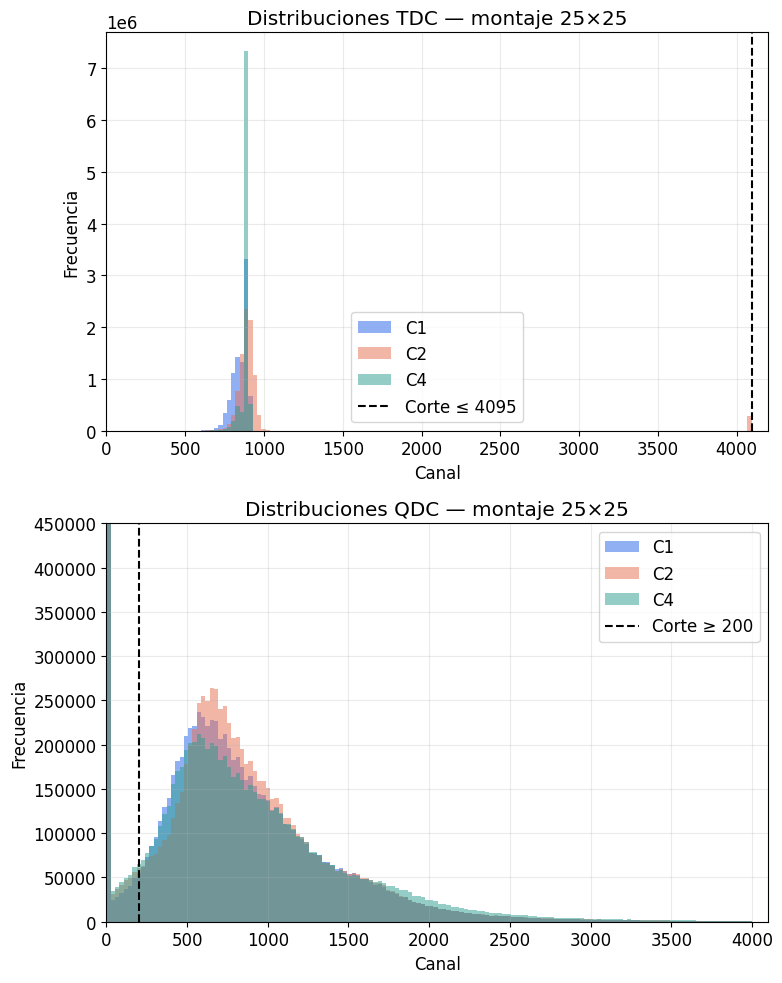

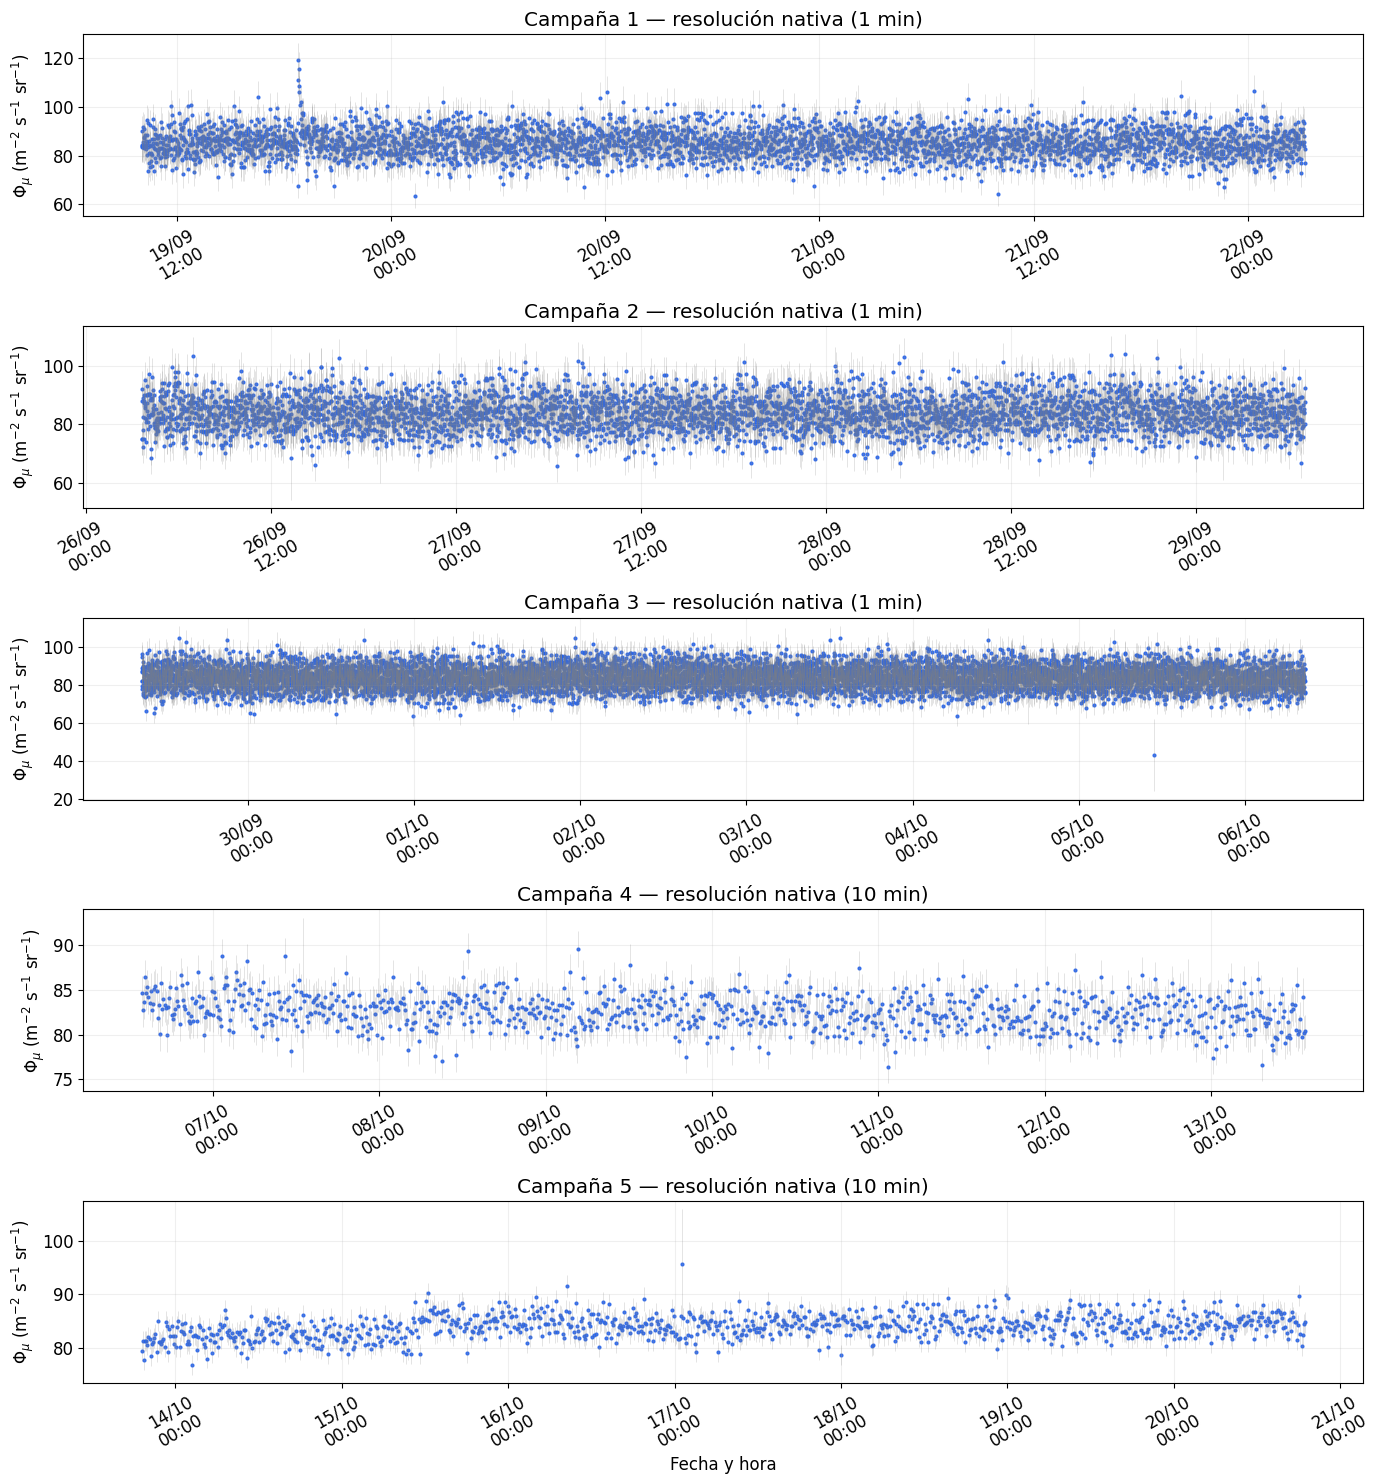

Archivos generados:
  - histogramas_TDC_QDC_25x25.pdf
  - flujo_nativo_25x25.pdf


In [ ]:
# ============================================================
# HISTOGRAMAS TDC/QDC + SERIES A RESOLUCIÓN NATIVA
# ============================================================

# ---------- Histogramas ----------
df_total = pd.concat(dataframes.values(), ignore_index=True)

fig, axes = plt.subplots(2, 1, figsize=(8, 10))
colores = {"C1": "#2563EB", "C2": "#E76F51", "C4": "#2A9D8F"}

# TDC
ax = axes[0]
for campo, label in [("campo_1", "C1"), ("campo_2", "C2"), ("campo_3", "C4")]:
    ax.hist(df_total[campo].dropna(), bins=150, range=(0, 4096),
            histtype="stepfilled", alpha=0.5, label=label, color=colores[label])
ax.axvline(4095, color="k", ls="--", lw=1.5, label="Corte ≤ 4095")
ax.set(title="Distribuciones TDC — montaje 25×25", xlabel="Canal", ylabel="Frecuencia", xlim=(0, 4200))
ax.legend(); ax.grid(alpha=0.25)

# QDC
ax = axes[1]
for campo, label in [("campo_5", "C1"), ("campo_6", "C2"), ("campo_7", "C4")]:
    ax.hist(df_total[campo].dropna(), bins=150, range=(0, 4000),
            histtype="stepfilled", alpha=0.5, label=label, color=colores[label])
ax.axvline(200, color="k", ls="--", lw=1.5, label="Corte ≥ 200")
ax.set(title="Distribuciones QDC — montaje 25×25", xlabel="Canal", ylabel="Frecuencia", xlim=(0, 4100))
ax.set_ylim(0, 450000)
ax.legend(); ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("histogramas_TDC_QDC_25x25.pdf", bbox_inches="tight")
plt.show()
del df_total

# ---------- Series a resolución nativa ----------
campanas = sorted(serie_flujo["campana"].unique())
fig, axes = plt.subplots(len(campanas), 1, figsize=(14, 3.0 * len(campanas)))

if len(campanas) == 1:
    axes = [axes]

for ax, campana in zip(axes, campanas):
    dfp = serie_flujo.loc[serie_flujo["campana"] == campana].sort_values("timestamp")
    ax.errorbar(dfp["timestamp"], dfp["Phi_mu"], yerr=dfp["sigma_Phi_mu"],
                fmt="none", ecolor="gray", alpha=0.25, elinewidth=0.6)
    ax.scatter(dfp["timestamp"], dfp["Phi_mu"], s=4, color="#2563EB", alpha=0.85)
    res = "1 min" if campana in [2, 3, 4] else "10 min"
    ax.set_title(f"Campaña {campana - 1} — resolución nativa ({res})")
    ax.set_ylabel(r"$\Phi_\mu$ (m$^{-2}$ s$^{-1}$ sr$^{-1}$)")
    ax.grid(alpha=0.2)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
    ax.tick_params(axis="x", rotation=30)

axes[-1].set_xlabel("Fecha y hora")
plt.tight_layout()
plt.savefig("flujo_nativo_25x25.pdf", bbox_inches="tight")
plt.show()

print("Archivos generados:")
print("  - histogramas_TDC_QDC_25x25.pdf")
print("  - flujo_nativo_25x25.pdf")